<a href="https://colab.research.google.com/github/Muthuvanesh/sales-performance-analytics-dashboard/blob/main/sales_performance_analytics_dashboard.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. AUTOMATIC LIVE FX CONVERSION SETUP
def get_live_rates_to_inr():
    fallback_rates = {
        'INR': 1.0,
        'USD': 83.50,
        'GBP': 105.80,
        'EUR': 90.20,
        'AUD': 54.80,
        'CAD': 61.30,
        'JPY': 0.54,
        'SGD': 62.10,
        'AED': 22.73,
        'SAR': 22.26
    }
    url = "https://open.er-api.com/v6/latest/INR"
    try:
        response = requests.get(url, timeout=5)
        response.raise_for_status()
        data = response.json()
        if data.get("result") == "success":
            rates = data.get("rates", {})
            live_rates = {curr: round(1.0 / rate, 4) for curr, rate in rates.items() if rate > 0}
            print(f"Live rates loaded (USD: ₹{live_rates.get('USD', 83.50)}, GBP: ₹{live_rates.get('GBP', 105.80)})")
            return live_rates
    except Exception as e:
        print(f"Live FX fetch failed ({e}). Using fallback rates.")
    return fallback_rates

EXCHANGE_RATES_TO_INR = get_live_rates_to_inr()

COUNTRY_TO_CURRENCY = {
    'United Kingdom': 'GBP',
    'United States': 'USD',
    'Germany': 'EUR',
    'France': 'EUR',
    'Spain': 'EUR',
    'Italy': 'EUR',
    'Netherlands': 'EUR',
    'Australia': 'AUD',
    'Canada': 'CAD',
    'Japan': 'JPY',
    'Singapore': 'SGD',
    'United Arab Emirates': 'AED',
    'Saudi Arabia': 'SAR',
    'India': 'INR'
}

DEFAULT_CURRENCY = 'USD'
DEFAULT_FX_RATE = EXCHANGE_RATES_TO_INR.get(DEFAULT_CURRENCY, 83.50)


In [ ]:
# 2. DATA INGESTION & AUDIT
df = pd.read_csv('messy_online_retail_3000.csv')

print("\n--- 1. DATASET OVERVIEW ---")
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Exact duplicate rows: {df.duplicated().sum()}")
print("\nMissing values count:")
print(df.isnull().sum())

# 3. SYSTEMATIC DATA CLEANING
df = df.drop_duplicates().reset_index(drop=True)

df['Category'] = df['Category'].astype(str).str.strip().str.title()
df['Category'] = df['Category'].replace(['Nan', 'None', 'nan', ''], np.nan)

country_mapping = {
    'uk': 'United Kingdom', 'UK': 'United Kingdom', 'UK ': 'United Kingdom',
    'usa': 'United States', 'USA': 'United States', 'U.S.A.': 'United States',
    'germany': 'Germany', 'australia': 'Australia'
}
df['Country'] = df['Country'].astype(str).str.strip().replace(country_mapping)
df['Country'] = df['Country'].replace(['Nan', 'None', 'nan', ''], np.nan)

def clean_unit_price(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).replace('$', '').replace('USD', '').replace('£', '').replace('€', '').strip()
    try:
        price = float(val_str)
        return price if 0 <= price <= 2000 else np.nan
    except ValueError:
        return np.nan

df['UnitPrice_Local'] = df['UnitPrice'].apply(clean_unit_price)

df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df.loc[(df['Quantity'] > 1000) | (df['Quantity'] < -100), 'Quantity'] = np.nan

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], errors='coerce')
df['CustomerID'] = df['CustomerID'].replace(['UNKNOWN', 'N/A', 'nan', 'None'], np.nan)

In [9]:
# 4. DYNAMIC CURRENCY CONVERSION & FEATURE ENGINEERING
df['Currency'] = df['Country'].map(COUNTRY_TO_CURRENCY).fillna(DEFAULT_CURRENCY)
df['FX_to_INR'] = df['Currency'].map(EXCHANGE_RATES_TO_INR).fillna(DEFAULT_FX_RATE)

df['UnitPrice_INR'] = df['UnitPrice_Local'] * df['FX_to_INR']
df['TotalPrice_Local'] = df['Quantity'] * df['UnitPrice_Local']
df['TotalPrice_INR'] = df['Quantity'] * df['UnitPrice_INR']

df['Year'] = df['InvoiceDate'].dt.year
df['Month'] = df['InvoiceDate'].dt.month
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour
df['YearMonth'] = df['InvoiceDate'].dt.to_period('M')

df['IsCancellation'] = df['InvoiceNo'].astype(str).str.startswith('C') | (df['Quantity'] < 0)

print(f"\nData cleaning & FX conversion complete. Cleaned shape: {df.shape}")

# 5. PREPARE ANALYTICAL SLICES
valid_df = df[
    df['InvoiceDate'].notnull() &
    (~df['IsCancellation']) &
    df['TotalPrice_INR'].notnull()
].copy()

traffic_df = df[df['InvoiceDate'].notnull()].copy()


Data cleaning & FX conversion complete. Cleaned shape: (2926, 22)


In [ ]:
# 6. VISUALIZATION 1: GMV BY PRODUCT CATEGORY (INR)
category_gmv_inr = (
    valid_df.groupby('Category')['TotalPrice_INR']
    .sum()
    .reset_index()
    .sort_values('TotalPrice_INR', ascending=False)
)

plt.figure(figsize=(11, 5))
ax = sns.barplot(
    data=category_gmv_inr,
    x='TotalPrice_INR',
    y='Category',
    palette='mako',
    edgecolor='#D3D3D3',
    linewidth=0.8
)

plt.title('Gross Merchandise Value (GMV) by Product Category (INR - ₹)', fontsize=13, fontweight='bold')
plt.xlabel('Total Revenue (₹)')
plt.ylabel('Category')
ax.grid(True, axis='x', color='#E5E5E5', linewidth=0.6, alpha=0.7)
ax.set_axisbelow(True)

for spine in ax.spines.values():
    spine.set_color('#CCCCCC')
    spine.set_linewidth(0.8)

for p in ax.patches:
    w = p.get_width()
    if w > 0:
        ax.annotate(
            f"₹{w:,.2f}",
            (w, p.get_y() + p.get_height() / 2),
            ha='left', va='center',
            xytext=(6, 0), textcoords='offset points',
            fontsize=9, fontweight='semibold'
        )

plt.xlim(0, category_gmv_inr['TotalPrice_INR'].max() * 1.25)
plt.tight_layout()
plt.show()

In [ ]:
# 7. VISUALIZATION 2: PEAK TRAFFIC (HOURLY & DAILY)
hourly_traffic = traffic_df.groupby('Hour').size().reset_index(name='Transaction_Count')

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
daily_traffic = (
    traffic_df.groupby('DayOfWeek')
    .size()
    .reindex(day_order, fill_value=0)
    .reset_index(name='Transaction_Count')
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ax1 = sns.lineplot(
    data=hourly_traffic,
    x='Hour',
    y='Transaction_Count',
    marker='o',
    color='teal',
    linewidth=2.5,
    ax=axes[0]
)
axes[0].set_title('Transaction Volume by Hour of Day', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Hour (24-Hour Format)')
axes[0].set_ylabel('Number of Transactions')
axes[0].set_xticks(range(0, 24))
axes[0].set_xlim(-0.5, 23.5)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].axvspan(9, 19, color='gold', alpha=0.15, label='Target Window (09:00 - 19:00)')
axes[0].legend(loc='upper right')

ax2 = sns.barplot(
    data=daily_traffic,
    x='DayOfWeek',
    y='Transaction_Count',
    palette='Blues_r',
    ax=axes[1]
)
axes[1].set_title('Transaction Volume by Day of the Week', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Number of Transactions')
axes[1].tick_params(axis='x', rotation=20)
axes[1].grid(True, axis='y', linestyle='--', alpha=0.5)

for p in ax2.patches:
    height = p.get_height()
    if height > 0:
        ax2.annotate(
            f"{int(height):,}",
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom',
            xytext=(0, 3), textcoords='offset points',
            fontsize=10, fontweight='semibold'
        )

axes[1].set_ylim(0, daily_traffic['Transaction_Count'].max() * 1.15)
plt.tight_layout()
plt.show()

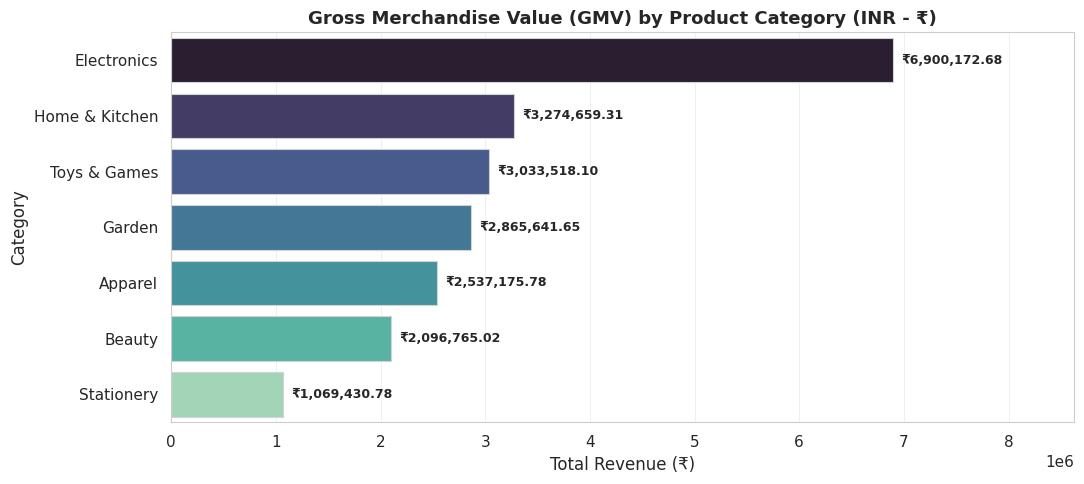

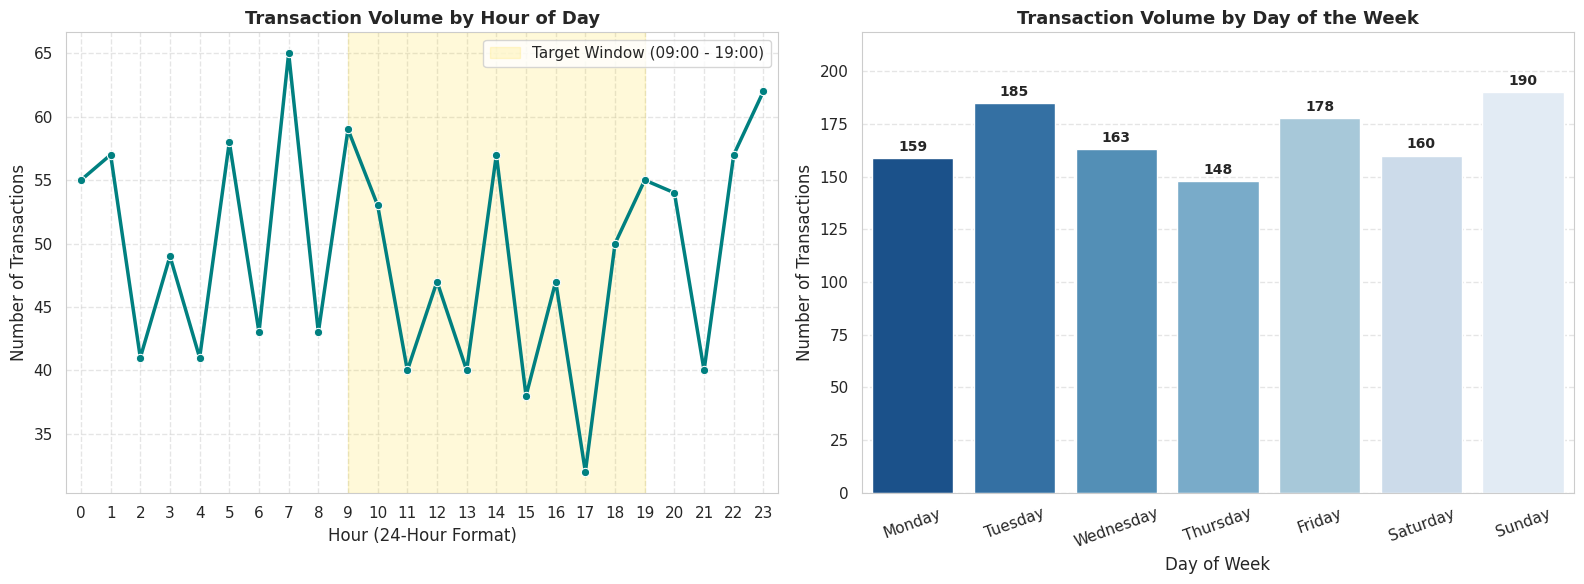

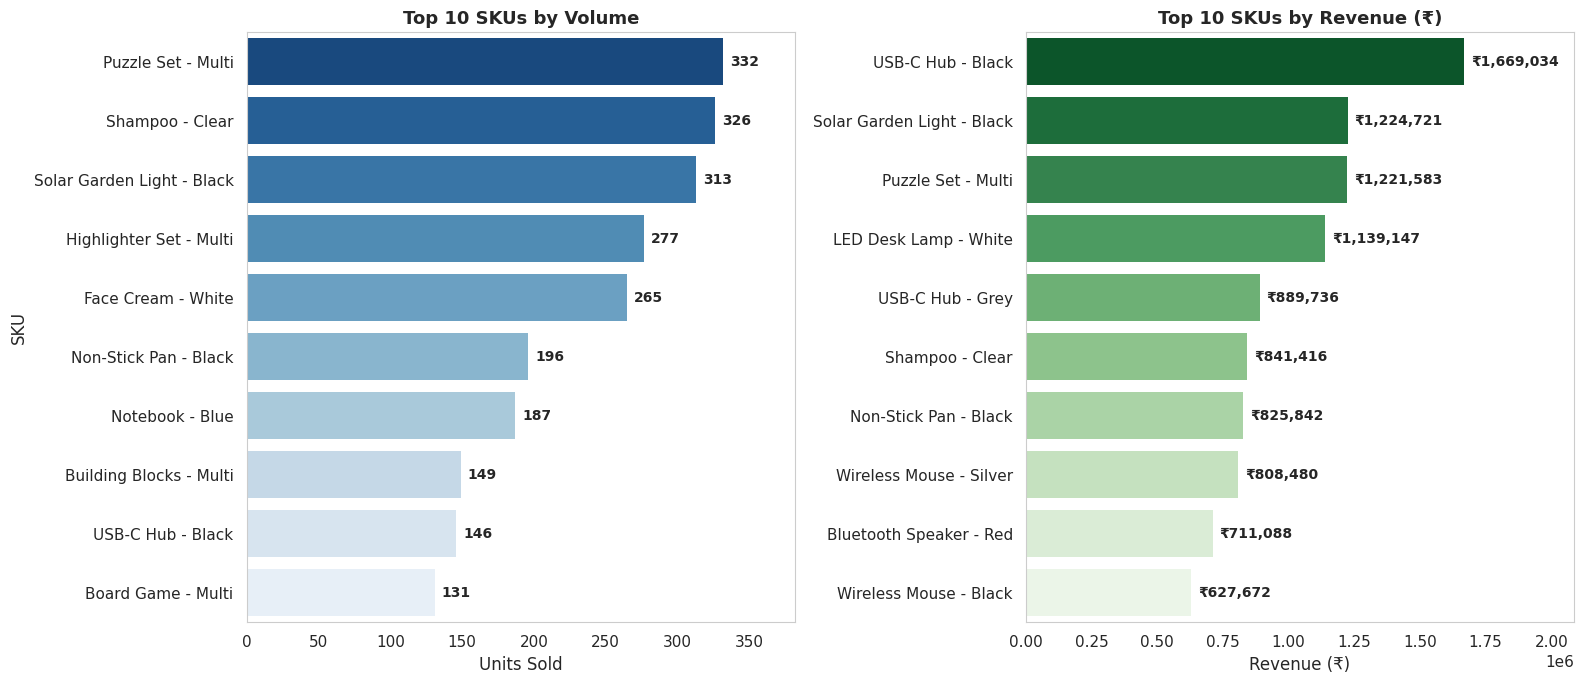

In [10]:
# 8. VISUALIZATION 3: TOP 10 SKUs (VOLUME VS. REVENUE IN INR)
sku_performance = valid_df.groupby('Description').agg(
    Total_Volume=('Quantity', 'sum'),
    Total_Revenue_INR=('TotalPrice_INR', 'sum')
).reset_index()

top_volume = sku_performance.sort_values('Total_Volume', ascending=False).head(10)
top_revenue = sku_performance.sort_values('Total_Revenue_INR', ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=top_volume,
    x='Total_Volume',
    y='Description',
    palette='Blues_r',
    edgecolor='none',
    ax=axes[0]
)
axes[0].set_title('Top 10 SKUs by Volume', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Units Sold')
axes[0].set_ylabel('SKU')
axes[0].grid(False)

for p in axes[0].patches:
    w = p.get_width()
    if w > 0:
        axes[0].annotate(
            f"{int(w):,}",
            (w, p.get_y() + p.get_height() / 2),
            ha='left', va='center',
            xytext=(5, 0), textcoords='offset points',
            fontsize=10, fontweight='bold'
        )

sns.barplot(
    data=top_revenue,
    x='Total_Revenue_INR',
    y='Description',
    palette='Greens_r',
    edgecolor='none',
    ax=axes[1]
)
axes[1].set_title('Top 10 SKUs by Revenue (₹)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Revenue (₹)')
axes[1].set_ylabel('')
axes[1].grid(False)

for p in axes[1].patches:
    w = p.get_width()
    if w > 0:
        axes[1].annotate(
            f"₹{w:,.0f}",
            (w, p.get_y() + p.get_height() / 2),
            ha='left', va='center',
            xytext=(5, 0), textcoords='offset points',
            fontsize=10, fontweight='bold'
        )

axes[0].set_xlim(0, top_volume['Total_Volume'].max() * 1.15)
axes[1].set_xlim(0, top_revenue['Total_Revenue_INR'].max() * 1.25)

plt.tight_layout()
plt.show()